In [29]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [44]:
# data is in above directory
sensors = ['Z-Axis Peak Velocity(mm/sec)', 'X-Axis Kurtosis', 'Frequency_L2_Current_Temperature', 'Frequency_L2_Z_Axis_Peak_Acceleration']
df_train = pd.read_csv("data/train_data.csv")
df_test = pd.read_csv("data/test_data.csv")
X_train = df_train[sensors]
y_train = df_train['machine_state']
X_test = df_test[sensors]
y_test = df_test['machine_state']


In [45]:
model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3)
model.fit(X_train, y_train)

GradientBoostingClassifier()

In [46]:
y_pred = model.predict(X_test)

              precision    recall  f1-score   support

           0       0.96      0.76      0.85     13422
           1       0.55      0.91      0.68      4284

    accuracy                           0.79     17706
   macro avg       0.75      0.83      0.77     17706
weighted avg       0.86      0.79      0.81     17706

Accuracy: 0.794532926691517


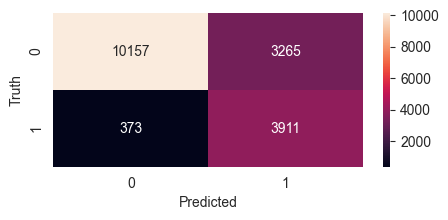

In [47]:
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
report = classification_report(y_test, y_pred)

# print them in a nice format using libraries for better visualization 
# imports
import seaborn as sns
import matplotlib.pyplot as plt



# print classification report
print(report)
print(f'Accuracy: {accuracy}')

# plot confusion matrix
plt.figure(figsize=(5, 2))
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.show()


In [28]:
def predict_state(m, predict, sensor='Temperature(DegC)'):
    predict = predict[sensor]

    predicted = m.predict(predict)

    # count the number of each state
    state = {}
    for i in predicted:
        if i not in state:
            state[i] = 1
        else:
            state[i] += 1

    print(state)
